# Set up your environment by importing needed libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    classification_report
)


## Using a new dataset called Diamonds Prices
### note: for the pandas library to be able to read your dataset, you need to add the dataset into your working directory by:
    - Using the input tab from the sidebar on the right on Kaggle
    - Finding your dataset
    - Clicking the add sign

In [2]:
df = pd.read_csv('/kaggle/input/datasets/nancyalaswad90/diamonds-prices/Diamonds Prices2022.csv',index_col=0)
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
# Basic cleaning steps 
# There are 149 duplicates so we will remove them first
df = df.drop_duplicates()
# We will use Ordinal Encoder which is a way to encode multiple columns at the
# same time and also control the labeling. (LabelEncoder will encode alphabetically)
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
color_order = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
clarity_order = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

# Create a binary column for whether the cut is Ideal as thats our target for classification
df['ideal_cut'] = (df['cut'] == 'Ideal').astype(int)

# Ordinal encode color and clarity only
encoder = OrdinalEncoder(categories=[color_order, clarity_order,cut_order])
df[['color', 'clarity','cut']] = encoder.fit_transform(df[['color', 'clarity','cut']])



df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,ideal_cut
1,0.23,4.0,5.0,1.0,61.5,55.0,326,3.95,3.98,2.43,1
2,0.21,3.0,5.0,2.0,59.8,61.0,326,3.89,3.84,2.31,0
3,0.23,1.0,5.0,4.0,56.9,65.0,327,4.05,4.07,2.31,0
4,0.29,3.0,1.0,3.0,62.4,58.0,334,4.20,4.23,2.63,0
5,0.31,1.0,0.0,1.0,63.3,58.0,335,4.34,4.35,2.75,0


# We will explore Classification and Regression on the same Dataset
### Let's start with Classification:
Choose which features will be the input(X) and what feature you are trying to predict(y)

In [4]:
#We will drop cut so we don't have any data leakage and predict whether the cut is ideal or not
X = df[['carat', 'color', 'clarity', 'depth', 'table','price','x','y','z']]  # You can modify this
y = df['ideal_cut']

## Splitting the Dataset is used to choose a portion of the data to train the model on, and another to test and evaluate your model after training:
    - test_size: specifies how much of the data will be used as test, the rest is training
    - random_state: setting it to the same number across runs ensures the random shuffling before the split is the same every time, so the train/test sets are consistent across runs.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Train a classification model: 
### The LogisticRegression class allows for the creation of a Logistic Regression model whose behavior can be altered by a number of optional parameters.  
    - max_iter: one of the optional parameters that dictates the maximum number of iterations. Theoretically, the more iterations the model makes the better the performance but is this always the case?
    - fit() method trains the model on the labeled data

## Hyper-parameter tuning:
Hyperparameter tuning is the process of finding the best set of hyperparameters (the model settings you choose before training) so that your machine learning model achieves the best performance on unseen data(think about the model's ability to generalize). Try experimenting with different parameters and inspecting the resulting metrics in order to make informed decisions to better the performance of your model.

In [6]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

## Evaluate the model:
    - Use the test dataset we got from the split and make the model predict its corresponding y values and compare it against the actual values

In [7]:
y_pred = logistic_model.predict(X_test)

- Recall -> can i recall all the positives? Useful when false positives arent an issue (Example COVID)
- Precisions -> are all my positives really positives? I need to be precise about my positives! Useful when false negatives arent an issue (Example youtube recommendations)

In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.7804628682963101
Precision: 0.7422254616132167
Recall: 0.7013314967860422
F1 Score: 0.7211992445703493

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.82      6403
           1       0.74      0.70      0.72      4356

    accuracy                           0.78     10759
   macro avg       0.77      0.77      0.77     10759
weighted avg       0.78      0.78      0.78     10759


Confusion Matrix:
[[5342 1061]
 [1301 3055]]


Visualize the confusion matrix.

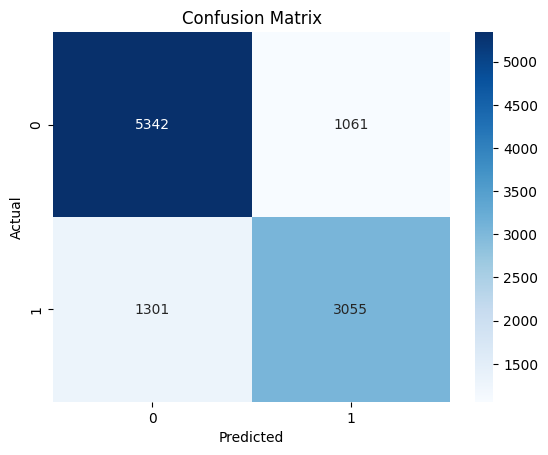

In [9]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Let's move on to Regression:
Choose which features will be the input(X) and what feature you are trying to predict(y)

In [10]:
#We will drop ideal_cut and use the normal cut column in order to predict the price
X = df[['carat', 'color', 'clarity', 'depth', 'table','cut','x','y','z']]  # You can modify this
y = df['price']

### Split the dataset

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

LinearRegression()

In [13]:
y_pred = linear_model.predict(X_test)

In [14]:
# Evaluate
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R²: {r2:.4f}")

MSE: 1402687.80
RMSE: 1184.35
MAE: 788.28
R²: 0.9080


### Graded Task

In [15]:
## Read the penguins dataset into a dataframe and do some basic cleaning
## before getting started!